# 37. Far player and controls under the sampler protocol (test, reporting seeds)

Where does the two player gain come from? Same question and decision rule as notebook 34, now run on the **paper protocol**: class balanced sampler (`target_per_class` from the recipe), advanced augmentation, **test set, reporting seeds 42, 123 and 7**, checkpoint chosen on validation. `near` and `both` are taken from notebook 36 (same clips, recipe, seeds, code path), not retrained.

| arm | what the model sees | what it tests |
|---|---|---|
| `far` | the far player only | how much the far player carries alone |
| `both_shuffled` | the real near player and the far player of a **different clip** (another class, same split) | if the gain survives, it is not the real opponent |
| `both_dup` | the near player twice (same weights, two feature vectors) | if the gain survives, it is the two vector structure, not a second player |

**Rule, fixed before running** (as in notebook 34). `retained = (control - near) / (both - near)` on test top-1, mean over seeds.
`retained <= 0.25`: the gain comes from the real far player. `retained >= 0.75`: it does not depend on the real far player. In between: mixed. The same ratio is shown for MCA.
Run notebook 36 first (`both/advanced` and `near/advanced` must be finished). 9 runs.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
for p in (REPO, f"{REPO}/two_player"):
    sys.path.insert(0, p)
import dataset as ds
import training as tr
import two_person as tp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/two_player_controls_sampler"
OLD_KP = f"{DATA}/keypoints_interp"
SEL_INTERP = f"{DATA}/keypoints_sel_interp"
OUT36 = f"{OUTPUTS}/experiments/two_player_sampler"
OUT = f"{OUTPUTS}/experiments/two_player_controls_sampler"
os.makedirs(OUT, exist_ok=True)

REPORT_SEEDS = [42, 123, 7]
SELECT_METRIC = "composite"
NORMALISATION, USE_COURT = "body", True
NUM_WORKERS, EVAL_WORKERS = 20, 8
FAR_COVERAGE_MIN = 0.5
DRILL_PATTERN = r"2023"
RARE_THRESHOLD = 150
N_BOOT = 2000
RETAINED_LOW, RETAINED_HIGH = 0.25, 0.75
CONTROL_ARMS = {"far": dict(root=SEL_INTERP, persons=(1,), donors=False),
                "both_shuffled": dict(root=SEL_INTERP, persons=(0, 1), donors=True),
                "both_dup": dict(root=SEL_INTERP, persons=(0, 0), donors=False)}

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
TARGET = RECIPE["target_per_class"]
print("class balanced sampler target_per_class =", TARGET)
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]

class balanced sampler target_per_class = 300


In [3]:
clean_log = pd.read_csv(f"{DATA}/keypoints_sel_interp_log.csv").set_index("filepath")
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
manifest = manifest[manifest["filepath"].isin(clean_log.index)].reset_index(drop=True)
manifest = manifest[clean_log.loc[manifest["filepath"], "near_cov"].to_numpy() > 0].reset_index(drop=True)
manifest["far_found"] = clean_log.loc[manifest["filepath"], "far_cov"].to_numpy() >= FAR_COVERAGE_MIN
manifest["drill"] = manifest["filepath"].str.contains(DRILL_PATTERN)
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
IN_CH = tp.n_channels(USE_COURT)
train_counts = manifest[manifest["split"] == "train"]["class_name"].value_counts().reindex(class_names)
rare_names = [c for c in class_names if train_counts[c] < RARE_THRESHOLD]
print(manifest["split"].value_counts().to_dict(), f"| {K} classes | {len(rare_names)} limited sample classes (under {RARE_THRESHOLD} train clips)")

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
{'train': 6247, 'test': 782, 'val': 781} | 18 classes | 8 limited sample classes (under 150 train clips)


In [4]:
res36 = pd.read_csv(f"{OUT36}/results_test.csv")
ref = res36[(res36["policy"] == "advanced") & res36["arm"].isin(["near", "both"]) & res36["seed"].isin(REPORT_SEEDS)]
assert all(((ref["arm"] == a)).sum() == len(REPORT_SEEDS) for a in ("near", "both")), "run notebook 36 first: near/advanced and both/advanced with all seeds"

## The shuffled far player

For every clip, a donor is drawn at random from the clips of **the same split, another class, with a real far player**. The clip keeps its own near player and its own label, and its far player is replaced by the donor's.
The draw is fixed (seed 0) so train, validation and every run see the same pairing. Using another class means the donor skeleton cannot carry the clip's label.
Augmentation still draws one set of random numbers for the pair, as in `both`.

In [5]:
def build_donors(manifest, seed=0):
    rng = np.random.RandomState(seed)
    donors = {}
    for split, part in manifest.groupby("split"):
        part = part.reset_index(drop=True)
        ok = part[part["far_found"]]
        for cls, g in part.groupby("class_name"):
            pool = ok[ok["class_name"] != cls]
            pick = pool.iloc[rng.randint(0, len(pool), size=len(g))]
            for fp, (dc, dfp) in zip(g["filepath"], zip(pick["class_name"], pick["filepath"])):
                donors[fp] = (dc, os.path.splitext(os.path.basename(dfp))[0])
    return donors


DONORS = build_donors(manifest)
lookup = manifest.set_index("filepath")
stem_to_row = {(r["class_name"], os.path.splitext(os.path.basename(fp))[0]): (fp, r) for fp, r in lookup.iterrows()}
checks = {"same split": 0, "other class": 0, "donor far found": 0, "not itself": 0}
for fp, (dc, ds_stem) in DONORS.items():
    dfp, drow = stem_to_row[(dc, ds_stem)]
    checks["same split"] += int(drow["split"] == lookup.loc[fp, "split"])
    checks["other class"] += int(dc != lookup.loc[fp, "class_name"])
    checks["donor far found"] += int(bool(drow["far_found"]))
    checks["not itself"] += int(dfp != fp)
print({k: f"{v}/{len(DONORS)}" for k, v in checks.items()})
assert all(v == len(DONORS) for v in checks.values())

{'same split': '7810/7810', 'other class': '7810/7810', 'donor far found': '7810/7810', 'not itself': '7810/7810'}


## Smoke test

All control arms build and run under the sampler, the shuffled far player differs from the clip's own, the duplicated player is identical in both slots.

In [6]:
tr.seed_everything(0)
part = manifest[manifest["split"] == "val"].reset_index(drop=True)
own = tp.PersonsDataset(part, SEL_INTERP, class_to_id, (0, 1), "none", NORMALISATION)
shuf = tp.PersonsDataset(part, SEL_INTERP, class_to_id, (0, 1), "none", NORMALISATION, donors=DONORS)
dup = tp.PersonsDataset(part, SEL_INTERP, class_to_id, (0, 0), "none", NORMALISATION)
i = int(np.where(part["far_found"].to_numpy())[0][0])
a, b, c = own[i], shuf[i], dup[i]
assert torch.equal(a["keypoints"][0], b["keypoints"][0]), "near player must be unchanged"
assert not torch.equal(a["keypoints"][1], b["keypoints"][1]), "far player must be replaced"
assert torch.equal(c["keypoints"][0], c["keypoints"][1]), "duplicated slots must match"
for name, cfg in CONTROL_ARMS.items():
    loaders = tp.build_loaders(manifest, cfg["root"], class_to_id, cfg["persons"], "advanced", seed=0, batch_size=RECIPE["batch_size"],
                               num_workers=2, eval_workers=2, donors=DONORS if cfg["donors"] else None, target_per_class=TARGET)
    batch = next(iter(loaders["train"]))
    model = tp.PersonsSTGCN(IN_CH, K, len(cfg["persons"])).to(device)
    logits = tp.make_forward(USE_COURT)(model, batch, device)
    nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])(logits, batch["label"].to(device)).backward()
    print(name, "ok", tuple(logits.shape))
    del model, loaders
print("smoke test passed")

far ok (16, 18)
both_shuffled ok (16, 18)
both_dup ok (16, 18)
smoke test passed


## Training

In [7]:
def run_ctrl(arm, cfg, seed, results_path, done, donors=None, splits=("train", "val", "test")):
    if ((done["arm"] == arm) & (done["seed"] == seed)).any():
        print(f"skip {arm} seed {seed}")
        return done
    run_name = f"c37_{arm}_s{seed}"
    print(f"\n=== {run_name} ===")
    tr.seed_everything(seed)
    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["two_player", "controls", "sampler_protocol", arm, f"seed{seed}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**RECIPE, "arm": arm, "persons": list(cfg["persons"]), "seed": seed, "select_metric": SELECT_METRIC, "balanced": True,
                  "target_per_class": TARGET, "policy": "advanced", "n_clips": len(manifest), "evaluated_splits": list(splits),
                  "shuffled_far": donors is not None, "split_sha256": split_hash})
    loaders = tp.build_loaders(manifest, cfg["root"], class_to_id, cfg["persons"], "advanced", seed=seed, batch_size=RECIPE["batch_size"],
                               num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS, splits=splits, donors=donors, target_per_class=TARGET)
    model = tp.PersonsSTGCN(IN_CH, K, len(cfg["persons"])).to(device)
    forward = tp.make_forward(USE_COURT)
    optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"], weight_decay=RECIPE["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=RECIPE.get("step_size", 10), gamma=RECIPE["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])
    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device, task.get_logger(),
                                            num_epochs=RECIPE["num_epochs"], patience=RECIPE.get("patience", 20),
                                            select_metric=SELECT_METRIC, splits=splits)
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=splits, show=False, extra={"arm": arm, "seed": seed})
    task.close()
    done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
    done.to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()
    return done

In [8]:
ctrl_path = f"{OUT}/results_test.csv"
ctrl_done = pd.read_csv(ctrl_path) if os.path.exists(ctrl_path) else pd.DataFrame(columns=["arm", "seed"])
for arm, cfg in CONTROL_ARMS.items():
    for seed in REPORT_SEEDS:
        ctrl_done = run_ctrl(arm, cfg, seed, ctrl_path, ctrl_done, donors=DONORS if cfg["donors"] else None)

skip far seed 42
skip far seed 123
skip far seed 7
skip both_shuffled seed 42
skip both_shuffled seed 123
skip both_shuffled seed 7
skip both_dup seed 42
skip both_dup seed 123
skip both_dup seed 7


## Results (test, mean +/- std over seeds; `near` and `both` from notebook 36)

In [9]:
ctrl = pd.read_csv(ctrl_path)
cols = ["test_top1", "test_mca", "test_macro_f1"]
allt = pd.concat([ref[["arm", "seed"] + cols], ctrl[["arm", "seed"] + cols]], ignore_index=True)
order = [a for a in ["far", "near", "both_dup", "both_shuffled", "both"] if (allt["arm"] == a).sum() == len(REPORT_SEEDS)]
mean, std = allt.groupby("arm")[cols].mean().reindex(order), allt.groupby("arm")[cols].std().reindex(order)
ctrl_table = (100 * mean).round(2).astype(str) + " +/- " + (100 * std).round(2).astype(str)
ctrl_table

,test_top1,test_mca,test_macro_f1
arm,,,
far,71.48 +/- 0.78,61.69 +/- 1.59,61.87 +/- 1.83
near,72.72 +/- 0.15,61.13 +/- 0.55,63.34 +/- 0.3
both_dup,72.68 +/- 1.16,61.75 +/- 1.43,63.19 +/- 1.45
both_shuffled,73.44 +/- 1.19,63.02 +/- 1.87,64.83 +/- 1.38
both,78.3 +/- 0.45,67.86 +/- 0.02,69.31 +/- 0.58


In [10]:
piv = {m: allt.pivot(index="seed", columns="arm", values=m) for m in ("test_top1", "test_mca")}
rows = []
for arm in ("both_dup", "both_shuffled"):
    if arm not in order:
        continue
    row = {"control": arm}
    for m, label in (("test_top1", "top1"), ("test_mca", "mca")):
        p = piv[m]
        gb, gc = (p["both"] - p["near"]).mean(), (p[arm] - p["near"]).mean()
        row[f"{label}: both - near (pts)"] = round(100 * gb, 2)
        row[f"{label}: control - near (pts)"] = round(100 * gc, 2)
        row[f"{label}: retained"] = round(float(gc / gb), 2) if gb > 0 else np.nan
    r = row["top1: retained"]
    row["reading (top1)"] = ("gain comes from the real far player" if r <= RETAINED_LOW else
                             "gain does not depend on the real far player" if r >= RETAINED_HIGH else "mixed")
    rows.append(row)
control_rule = pd.DataFrame(rows)
print(f"rule: retained <= {RETAINED_LOW} -> real far player; >= {RETAINED_HIGH} -> not the real far player; otherwise mixed")
control_rule

rule: retained <= 0.25 -> real far player; >= 0.75 -> not the real far player; otherwise mixed


,control,top1: both - near (pts),top1: control - near (pts),top1: retained,mca: both - near (pts),mca: control - near (pts),mca: retained,reading (top1)
0,both_dup,5.58,-0.04,-0.01,6.73,0.62,0.09,gain comes from the real far player
1,both_shuffled,5.58,0.72,0.13,6.73,1.89,0.28,gain comes from the real far player


In [11]:
def pred_dir(arm, s):
    return (f"{OUT36}/t36_{arm}_advanced_s{s}/t36_{arm}_advanced_s{s}" if arm in ("near", "both") else f"{OUT}/c37_{arm}_s{s}/c37_{arm}_s{s}")

def load_arm(arm):
    out = {}
    for s in REPORT_SEEDS:
        p = pd.read_csv(pred_dir(arm, s) + "_predictions.csv")
        out[s] = p[p["split"] == "test"].sort_values("filepath").reset_index(drop=True)
    return out

P = {a: load_arm(a) for a in order}
files = P[order[0]][REPORT_SEEDS[0]]["filepath"].to_numpy()
for a in order:
    for s in REPORT_SEEDS:
        assert (P[a][s]["filepath"].to_numpy() == files).all()
y = P[order[0]][REPORT_SEEDS[0]]["label"].map(class_to_id).to_numpy()
Y = {a: {s: P[a][s]["pred"].map(class_to_id).to_numpy() for s in REPORT_SEEDS} for a in order}
def top1(yt, yp): return float((yt == yp).mean())
def mca(yt, yp):
    tot = np.bincount(yt, minlength=K); hit = np.bincount(yt[yt == yp], minlength=K)
    return float((hit[tot > 0] / tot[tot > 0]).mean())
def seed_mean(a, idx, fn): return float(np.mean([fn(y[idx], Y[a][s][idx]) for s in REPORT_SEEDS]))
def boot_diff(a, b, fn, n_boot=N_BOOT, seed=0):
    rng = np.random.RandomState(seed); full = np.arange(len(y))
    point = seed_mean(a, full, fn) - seed_mean(b, full, fn); d = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.randint(0, len(y), len(y)); d[i] = seed_mean(a, idx, fn) - seed_mean(b, idx, fn)
    lo, hi = np.percentile(d, [2.5, 97.5]); return point, lo, hi
rows = []
for a, b in (("both", "near"), ("both_shuffled", "near"), ("both_dup", "near"), ("both", "both_shuffled"), ("both", "both_dup"), ("far", "near")):
    if a not in order or b not in order:
        continue
    row = {"comparison": f"{a} - {b}"}
    for fn, label in ((top1, "top1"), (mca, "mca")):
        pt, lo, hi = boot_diff(a, b, fn)
        row[f"{label} (pts)"] = round(100 * pt, 2); row[f"{label} 95% CI"] = f"[{100 * lo:+.2f}, {100 * hi:+.2f}]"
    rows.append(row)
diffs = pd.DataFrame(rows)
diffs

,comparison,top1 (pts),top1 95% CI,mca (pts),mca 95% CI
0,both - near,5.58,"[+3.66, +7.50]",6.73,"[+3.58, +9.92]"
1,both_shuffled - near,0.72,"[-0.72, +2.13]",1.89,"[-0.48, +4.25]"
2,both_dup - near,-0.04,"[-1.36, +1.24]",0.62,"[-1.19, +2.51]"
3,both - both_shuffled,4.86,"[+2.86, +6.82]",4.84,"[+1.60, +8.00]"
4,both - both_dup,5.63,"[+3.67, +7.54]",6.11,"[+3.36, +8.91]"
5,far - near,-1.24,"[-3.88, +1.45]",0.56,"[-3.46, +4.60]"


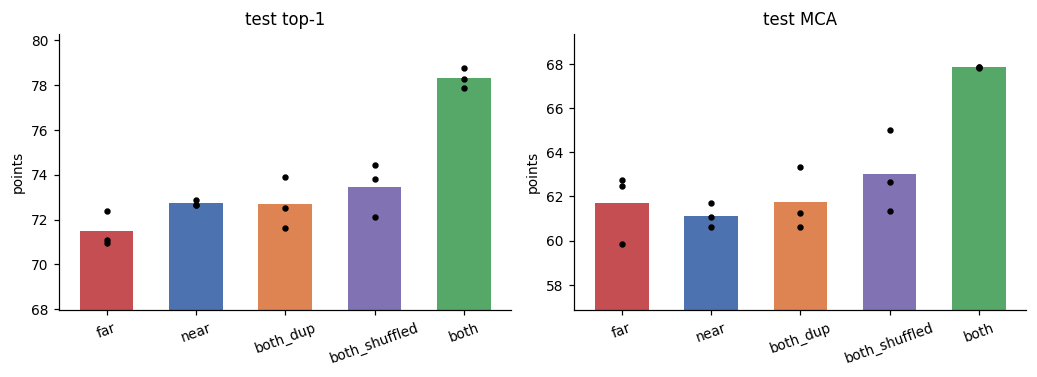

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.5))
colors = {"far": "#c44e52", "near": "#4c72b0", "both_dup": "#dd8452", "both_shuffled": "#8172b3", "both": "#55a868"}
for ax, m, title in zip(axes, ("test_top1", "test_mca"), ("test top-1", "test MCA")):
    for j, a in enumerate(order):
        v = 100 * piv[m][a].to_numpy()
        ax.bar(j, v.mean(), color=colors[a], width=0.6); ax.scatter([j] * len(v), v, color="k", s=10, zorder=3)
    ax.set_xticks(range(len(order)), order, rotation=20)
    ax.set_ylim(100 * piv[m][order].min().min() - 3, 100 * piv[m][order].max().max() + 1.5)
    ax.set_title(title); ax.set_ylabel("points")
fig.tight_layout(); plt.show()

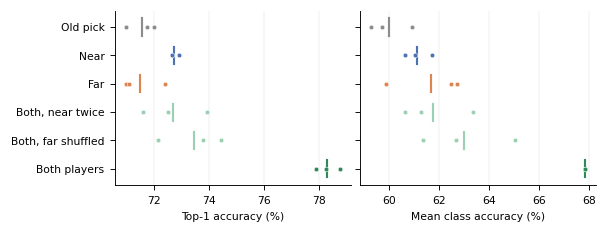

In [13]:
# Paper figure: test top-1 and MCA per seed for every arm (advanced augmentation)
FIG_DIR = f"{REPO}/paper_figures"; os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"font.size": 7, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
                     "ytick.major.width": 0.6, "axes.spines.top": False, "axes.spines.right": False})

# old pick comes from notebook 36
rt36 = pd.read_csv(f"{OUT36}/results_test.csv")
old = rt36[(rt36["arm"] == "old_pick") & (rt36["policy"] == "advanced")].set_index("seed").loc[REPORT_SEEDS]

arms = [("Old pick", "#8c8c8c", "old_pick"), ("Near", "#4C72B0", "near"), ("Far", "#DD8452", "far"),
        ("Both, near twice", "#9bd1b0", "both_dup"), ("Both, far shuffled", "#9bd1b0", "both_shuffled"),
        ("Both players", "#2E8B57", "both")]

def seed_values(arm, metric):
    if arm == "old_pick":
        return 100 * old[metric].to_numpy()
    return 100 * piv[metric].loc[REPORT_SEEDS, arm].to_numpy()

fig, axs = plt.subplots(1, 2, figsize=(5.4, 2.0), sharey=True)
for ax, metric, title in zip(axs, ("test_top1", "test_mca"), ("Top-1 accuracy (%)", "Mean class accuracy (%)")):
    for r, (label, color, arm) in enumerate(arms):
        v = seed_values(arm, metric); yy = len(arms) - 1 - r
        ax.plot([v.mean()] * 2, [yy - 0.3, yy + 0.3], color=color, lw=1.4)
        ax.scatter(v, [yy] * len(v), s=9, color=color, zorder=3, edgecolor="white", lw=0.3)
    ax.set_xlabel(title); ax.grid(axis="x", lw=0.3, color="#dddddd"); ax.set_axisbelow(True)
axs[0].set_yticks(range(len(arms))); axs[0].set_yticklabels([a[0] for a in arms][::-1])
fig.tight_layout(pad=0.4)
fig.savefig(f"{FIG_DIR}/fig_controls.png", dpi=300)
plt.show()

In [15]:
print(ctrl[["arm","seed","test_top1","test_top5","test_mca","test_macro_f1"]].sort_values(["arm","seed"]).round(2).to_string(index=False))

          arm  seed  test_top1  test_top5  test_mca  test_macro_f1
     both_dup     7       0.74       0.95      0.63           0.65
     both_dup    42       0.73       0.95      0.61           0.62
     both_dup   123       0.72       0.94      0.61           0.63
both_shuffled     7       0.74       0.95      0.65           0.66
both_shuffled    42       0.72       0.93      0.63           0.64
both_shuffled   123       0.74       0.94      0.61           0.64
          far     7       0.71       0.94      0.60           0.60
          far    42       0.72       0.94      0.63           0.63
          far   123       0.71       0.94      0.62           0.62


In [16]:
print((100*ctrl.groupby("arm")[["test_top5"]].mean()).round(2))
rare_idx = [class_names.index(c) for c in rare_names]
common_idx = [i for i in range(K) if i not in rare_idx]
for a in order:
    R = np.mean([[ (Y[a][s][y==k]==k).mean() for k in range(K)] for s in REPORT_SEEDS], axis=0)
    print(a, "limited", round(100*R[rare_idx].mean(),2), "common", round(100*R[common_idx].mean(),2))

               test_top5
arm                     
both_dup           94.37
both_shuffled      94.20
far                94.08
far limited 55.76 common 66.43
near limited 51.14 common 69.12
both_dup limited 53.01 common 68.74
both_shuffled limited 54.88 common 69.53
both limited 60.37 common 73.85


In [14]:
assert set(order) == {"far", "near", "both_dup", "both_shuffled", "both"}, f"run all control arms first (done: {order})"
decision = {"experiment": "two_player_controls_sampler", "report_seeds": REPORT_SEEDS, "target_per_class": TARGET,
            "test_mean": {a: {k: float(mean.loc[a, k]) for k in cols} for a in order},
            "controls_rule": control_rule.to_dict(orient="records"), "differences": diffs.to_dict(orient="records")}
os.makedirs(f"{REPO}/configs", exist_ok=True)
with open(f"{REPO}/configs/two_player_controls_sampler.json", "w") as f:
    json.dump(decision, f, indent=2, default=str)
task = Task.init(project_name=PROJECT, task_name="controls_sampler_summary", task_type=Task.TaskTypes.qc,
                 tags=["two_player", "controls", "sampler_protocol", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
log = task.get_logger(); task.connect({**RECIPE, "report_seeds": REPORT_SEEDS, "split_sha256": split_hash})
log.report_table("controls test", "test", iteration=0, table_plot=ctrl_table.reset_index())
log.report_table("controls rule", "test", iteration=0, table_plot=control_rule)
log.report_table("differences", "test", iteration=0, table_plot=diffs)
log.report_matplotlib_figure("controls", "test", figure=fig, iteration=0, report_interactive=False)
task.upload_artifact("decision", artifact_object=f"{REPO}/configs/two_player_controls_sampler.json")
task.close()
print("saved configs/two_player_controls_sampler.json")

ClearML Task: created new task id=6a7d68f9ab894cb9a11a5e723e0d4108
2026-10-10 15:34:40,054 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/a9122213b2124c109bc1b17e4742b90a/tasks/6a7d68f9ab894cb9a11a5e723e0d4108/output/log
saved configs/two_player_controls_sampler.json
